In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

plt.rcParams['figure.figsize'] = (12,5)
plt.rcParams['axes.grid'] = True

In [ ]:
data = yf.download(tickers='SPY',period='max',interval='1mo',auto_adjust=True,progress=False)
data

Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
1993-01-01,24.053547,24.070655,23.950900,24.070655,1003200
1993-02-01,24.310152,24.703631,23.437655,24.070643,5417600
1993-03-01,24.854677,25.215637,24.321831,24.510906,3019200
1993-04-01,24.218695,24.889049,23.806169,24.889049,2697200
1993-05-01,24.871864,25.112504,24.115567,24.253076,1808000
...,...,...,...,...,...
2026-06-01,744.920227,758.516470,714.805007,753.488915,1314920000
2026-07-01,745.179626,753.708436,727.293986,743.154626,1064946100


In [ ]:
rets = data['Close']['SPY']
rets

,SPY
Date,
1993-01-01,24.053547
1993-02-01,24.310152
1993-03-01,24.854677
1993-04-01,24.218695
1993-05-01,24.871864
...,...
2026-06-01,744.920227
2026-07-01,745.179626
2026-08-01,765.149963


In [ ]:
type(rets)

pandas.core.series.Series

In [ ]:
print(f'{len(rets)} observaciones mensuales: {rets.index.min():%Y-%m} a {rets.index.max():%Y-%m}')

406 observaciones mensuales: 1993-01 a 2026-10


In [ ]:
data_multi = yf.download(tickers=['SPY','BND'],period='max',interval='1mo',auto_adjust=True,progress=False)
rets = data_multi['Close']
rets

Ticker,BND,SPY
Date,,
1993-01-01,NaN,24.053524
1993-02-01,NaN,24.310146
1993-03-01,NaN,24.854664
1993-04-01,NaN,24.218704
1993-05-01,NaN,24.871864
...,...,...
2026-06-01,72.397507,744.920227
2026-07-01,71.471336,745.179626
2026-08-01,71.731483,765.149963


In [ ]:
type(data_multi)

pandas.core.frame.DataFrame

In [ ]:
rets = rets.dropna()
rets

Ticker,BND,SPY
Date,,
2007-04-01,40.788139,103.862534
2007-05-01,40.467182,107.385567
2007-06-01,40.341179,105.815567
2007-07-01,40.713287,102.502441
2007-08-01,41.317192,103.817787
...,...,...
2026-06-01,72.397507,744.920227
2026-07-01,71.471336,745.179626
2026-08-01,71.731483,765.149963


In [ ]:
rets = rets.to_period('M')

mes_actual = pd.Timestamp.today().to_period('M')
rets = rets[rets.index < mes_actual]
rets

Ticker,BND,SPY
Date,,
2007-04,40.788139,103.862534
2007-05,40.467182,107.385567
2007-06,40.341179,105.815567
2007-07,40.713287,102.502441
2007-08,41.317192,103.817787
...,...,...
2026-05,72.203217,752.667114
2026-06,72.397507,744.920227
2026-07,71.471336,745.179626


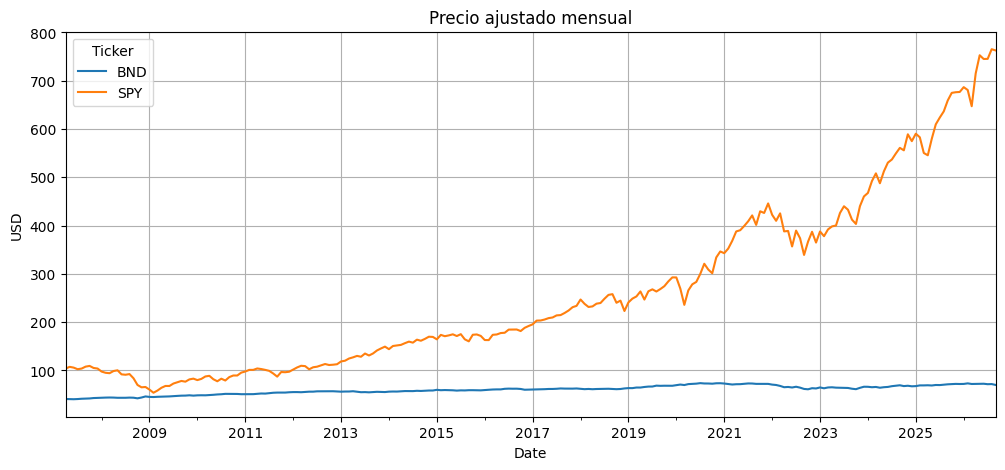

In [ ]:
rets.plot(title='Precio ajustado mensual',ylabel='USD')
plt.show()

##Single period returns

Return from time period $i$ (initial) to $f$ (final):

$$R_{i,f} = \frac{P_{f}-P_{i}}{P_{i}}$$

Que es igual:
$$R_{i,f} = \frac{P_{f}}{P_{i}}-1$$


##Multi period returns

$$R_{t_1,t_3} = (1+R_{t_1,t_2})(1+R_{t_2,t_3})-1$$

In [ ]:
#convertimos precios a retornos

rets = rets.pct_change().dropna()
rets

Ticker,BND,SPY
Date,,
2007-05,-0.007869,0.033920
2007-06,-0.003114,-0.014620
2007-07,0.009224,-0.031310
2007-08,0.014833,0.012832
2007-09,0.006035,0.038714
...,...,...
2026-05,0.002757,0.052626
2026-06,0.002691,-0.010293
2026-07,-0.012793,0.000348


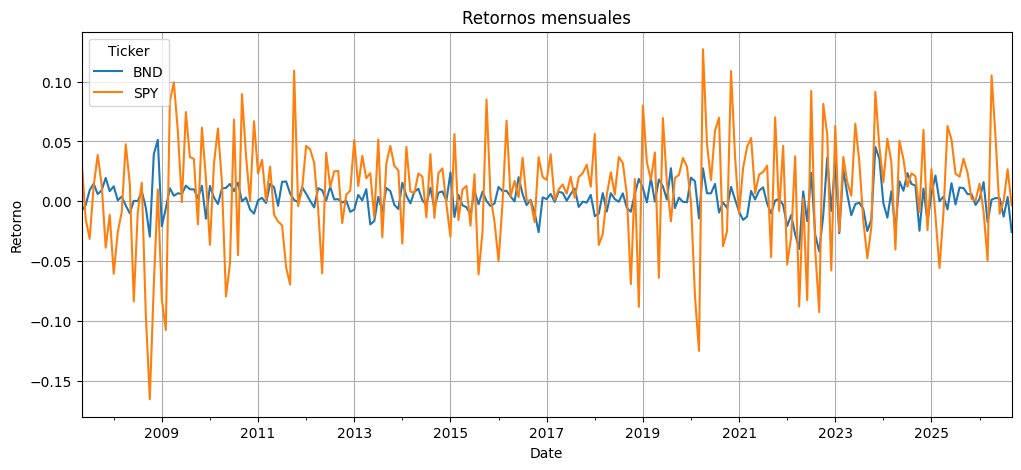

In [ ]:
rets.plot(title="Retornos mensuales",ylabel='Retorno')
plt.show()

In [ ]:
compound_returns = (rets+1).prod()-1
(compound_returns*100).round(2).astype('str')+'%'

,0
Ticker,
BND,71.38%
SPY,634.27%


In [ ]:
rets.head(10)

Ticker,BND,SPY
Date,,
2007-05,-0.007869,0.033920
2007-06,-0.003114,-0.014620
2007-07,0.009224,-0.031310
2007-08,0.014833,0.012832
2007-09,0.006035,0.038714
2007-10,0.009190,0.013567
2007-11,0.019588,-0.038733
2007-12,0.008467,-0.011261
2008-01,0.012536,-0.060461


In [ ]:
rets.tail(10)

Ticker,BND,SPY
Date,,
2025-12,-0.003002,0.000797
2026-01,0.002160,0.014738
2026-02,0.016017,-0.008642
2026-03,-0.017374,-0.049380
2026-04,0.001499,0.105053
2026-05,0.002757,0.052626
2026-06,0.002691,-0.010293
2026-07,-0.012793,0.000348
2026-08,0.003640,0.026799


In [ ]:
rets.size

466

In [ ]:
rets.shape

(233, 2)

In [ ]:
rets.iloc[20:24]

Ticker,BND,SPY
Date,,
2009-01,-0.020767,-0.082114
2009-02,-0.005854,-0.107449
2009-03,0.010941,0.083311
2009-04,0.004658,0.099346


In [ ]:
rets.loc['2009-01':'2009-04']

Ticker,BND,SPY
Date,,
2009-01,-0.020767,-0.082114
2009-02,-0.005854,-0.107449
2009-03,0.010941,0.083311
2009-04,0.004658,0.099346


##Medidas de riesgo

Varianza:

$$\sigma^2 = \frac{1}{N} {\sum_{i=1}^{N}(R_i-\mu)^2} $$

Desviación estándar -> Raíz cuadrada de la varianza

In [ ]:
rets.std()

,0
Ticker,
BND,0.013204
SPY,0.044646


In [ ]:
n_periods = rets.shape[0]
compounded_growth = (1+rets).prod()
monthly_ret = compounded_growth**(1/n_periods) - 1
(monthly_ret+1)**12 -1

,0
Ticker,
BND,0.028132
SPY,0.108137


In [ ]:
def annualize_rets(rets,periods_per_year=12):
  compounded_growth = (1+rets).prod()
  n_periods = rets.shape[0]
  return compounded_growth**(periods_per_year/n_periods) -1

In [ ]:
annualize_rets(rets)

,0
Ticker,
BND,0.028132
SPY,0.108137


Desviación estándar anualizada

$$\sigma * \sqrt{p}$$

In [ ]:
def annualize_vol(rets,periods_per_year=12):
    return rets.std()*(periods_per_year**0.5)

In [ ]:
annualize_vol(rets)

,0
Ticker,
BND,0.045741
SPY,0.154657


Sharpe Ratio

In [ ]:
# Raw Sharpe Ratio (sin restar la tasa libre de riesgo)
annualize_rets(rets) / annualize_vol(rets)

,0
Ticker,
BND,0.615031
SPY,0.699204


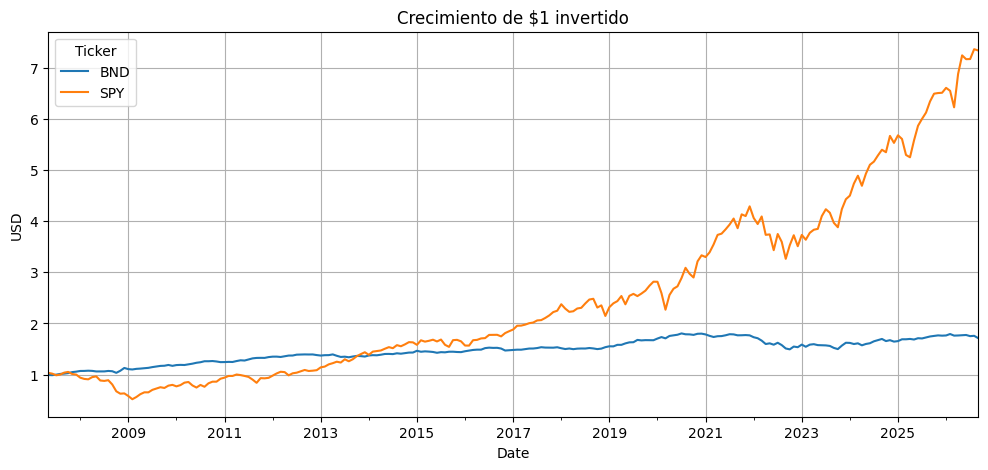

In [ ]:
# Growth of 1 dollar
wealth_index = (1+rets).cumprod()
wealth_index.plot(title='Crecimiento de $1 invertido', ylabel='USD')
plt.show()

In [ ]:
# Para el drawdown usamos solo SPY con toda su historia (desde 1993)
data_spy = yf.download(tickers='SPY', period='max', interval='1mo', auto_adjust=True, progress=False)
precios_spy = data_spy['Close']['SPY']  # Serie 1D
precios_spy = precios_spy[precios_spy.index < pd.Timestamp.today().to_period('M').to_timestamp()]  # sin el mes en curso
rets = precios_spy.pct_change().dropna()

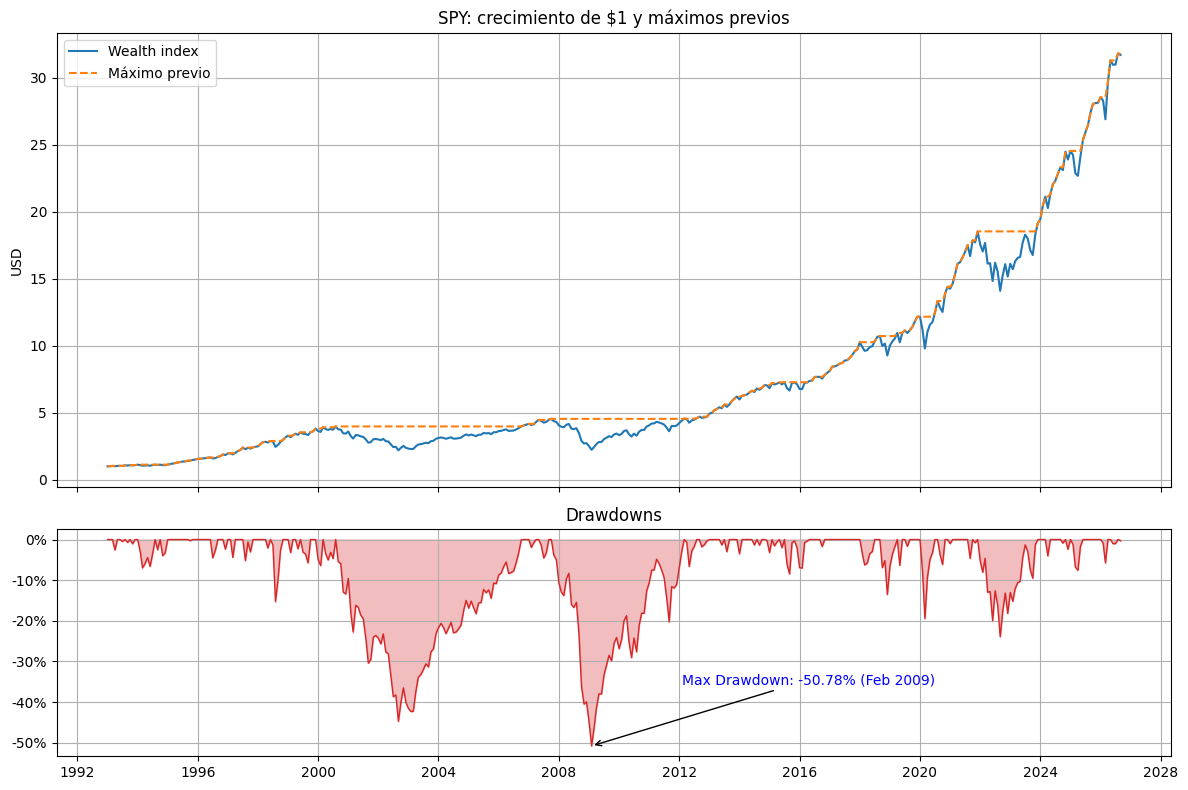

In [ ]:
wealth_index = (1+rets).cumprod()
# Agregamos el punto inicial ($1) un mes antes del primer retorno
start_date = wealth_index.index.min() - pd.DateOffset(months=1)
wealth_index = pd.concat([pd.Series([1.0], index=[start_date]), wealth_index])

previous_peaks = wealth_index.cummax()
drawdowns = (wealth_index - previous_peaks)/previous_peaks

max_drawdown = drawdowns.min()
max_drawdown_date = drawdowns.idxmin()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})
ax1.plot(wealth_index, label='Wealth index')
ax1.plot(previous_peaks, label='Máximo previo', linestyle='--')
ax1.set_title('SPY: crecimiento de $1 y máximos previos')
ax1.set_ylabel('USD')
ax1.legend()

ax2.fill_between(drawdowns.index, drawdowns, 0, color='tab:red', alpha=0.3)
ax2.plot(drawdowns, color='tab:red', lw=1)
ax2.annotate(f'Max Drawdown: {max_drawdown:.2%} ({max_drawdown_date:%b %Y})',
             xy=(max_drawdown_date, max_drawdown),
             xytext=(max_drawdown_date + pd.DateOffset(years=3), max_drawdown * 0.7),
             arrowprops=dict(arrowstyle='->', lw=1), color='blue')
ax2.set_title('Drawdowns')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.tight_layout()
plt.show()